<center><h1>Hu_Tianyang_HW5</h1></center>
<br>
<br>

Name: Tianyang Hu
<br>
Github Username: hhuhhuhhuhhu
<br>
USC ID: 2203816542

## 1. Decision Trees as Interpretable Models

Import packages

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, accuracy_score

### (a) Obtain Data

Get the Accute Inamations Data Set

In [6]:
columns = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pain",
    "burning",
    "bladder_inflammation",
    "nephritis"
]

diagnosis = pd.read_csv(
    "diagnosis.data",
    sep="\t",
    encoding="utf-16",
    decimal=",",
    header=None,
    names=columns
)

for col in columns[1:]:
    diagnosis[col] = diagnosis[col].map({"yes": 1, "no": 0})

display(diagnosis.head())

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,burning,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

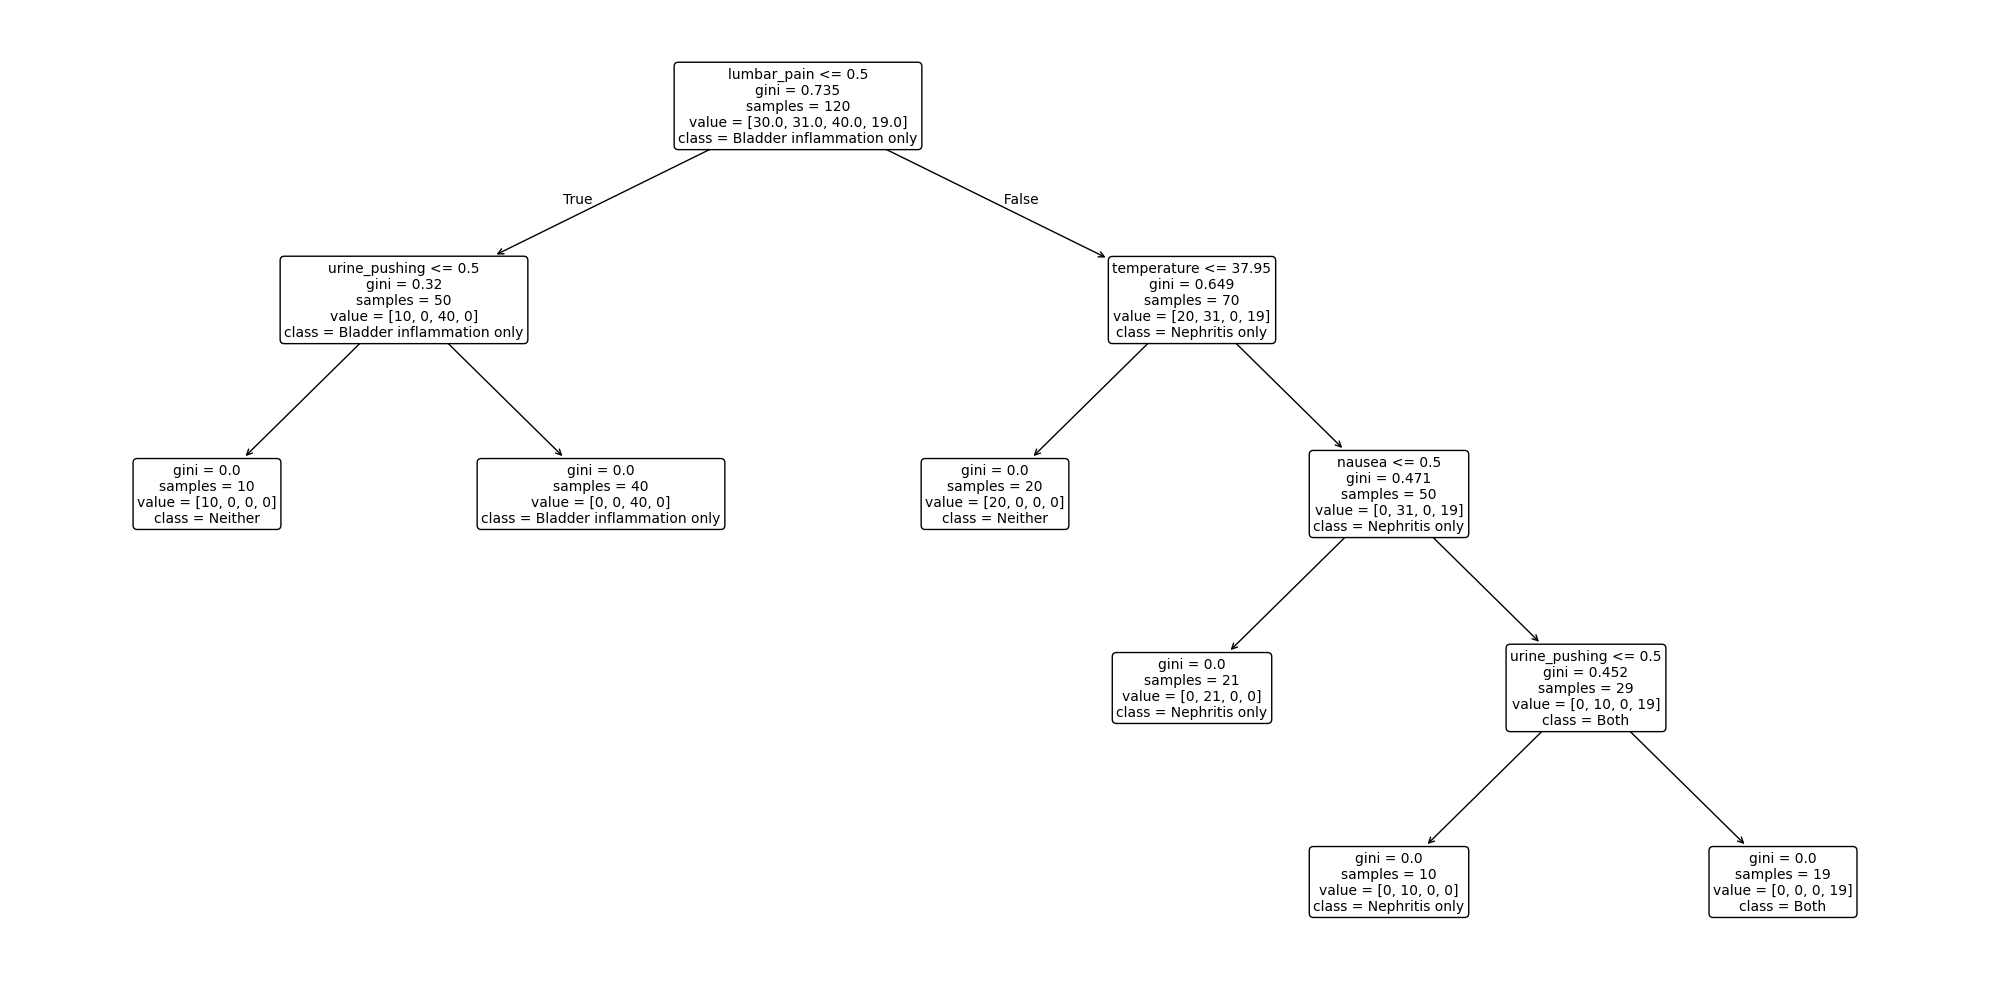

In [7]:
X = diagnosis.iloc[:, :6]
y = (
    diagnosis["bladder_inflammation"].astype(str)
    + diagnosis["nephritis"].astype(str)
)

class_labels = {
    "00": "Neither",
    "01": "Nephritis only",
    "10": "Bladder inflammation only",
    "11": "Both"
}

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X, y)

plt.figure(figsize=(20, 10))
plot_tree(
    tree,
    feature_names=X.columns.tolist(),
    class_names=[class_labels[c] for c in tree.classes_],
    filled=False,
    rounded=True,
    fontsize=10
)
plt.tight_layout()
plt.show()

### (c) Convert the decision rules

In [8]:
def print_rules(model, feature_names):
    t = model.tree_

    def walk(node, conditions):
        if t.children_left[node] == t.children_right[node]:
            label = model.classes_[np.argmax(t.value[node][0])]
            rule = " AND ".join(conditions) if conditions else "TRUE"
            print(f"IF {rule} THEN {class_labels[label]}")
            return

        feature = feature_names[t.feature[node]]
        threshold = t.threshold[node]

        walk(
            t.children_left[node],
            conditions + [f"{feature} <= {threshold:.2f}"]
        )
        walk(
            t.children_right[node],
            conditions + [f"{feature} > {threshold:.2f}"]
        )

    walk(0, [])

print_rules(tree, X.columns.tolist())

IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN Neither
IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN Bladder inflammation only
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN Neither
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea <= 0.50 THEN Nephritis only
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing <= 0.50 THEN Nephritis only
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing > 0.50 THEN Both


### (d)

,alpha,cv_accuracy
0,0.000000,0.991667
1,0.098167,0.858333
2,0.133333,0.758333
3,0.182000,0.666667
4,0.222917,0.483333


Selected alpha: 0.0
Original leaves: 6
Pruned leaves: 6
Training accuracy: 1.0


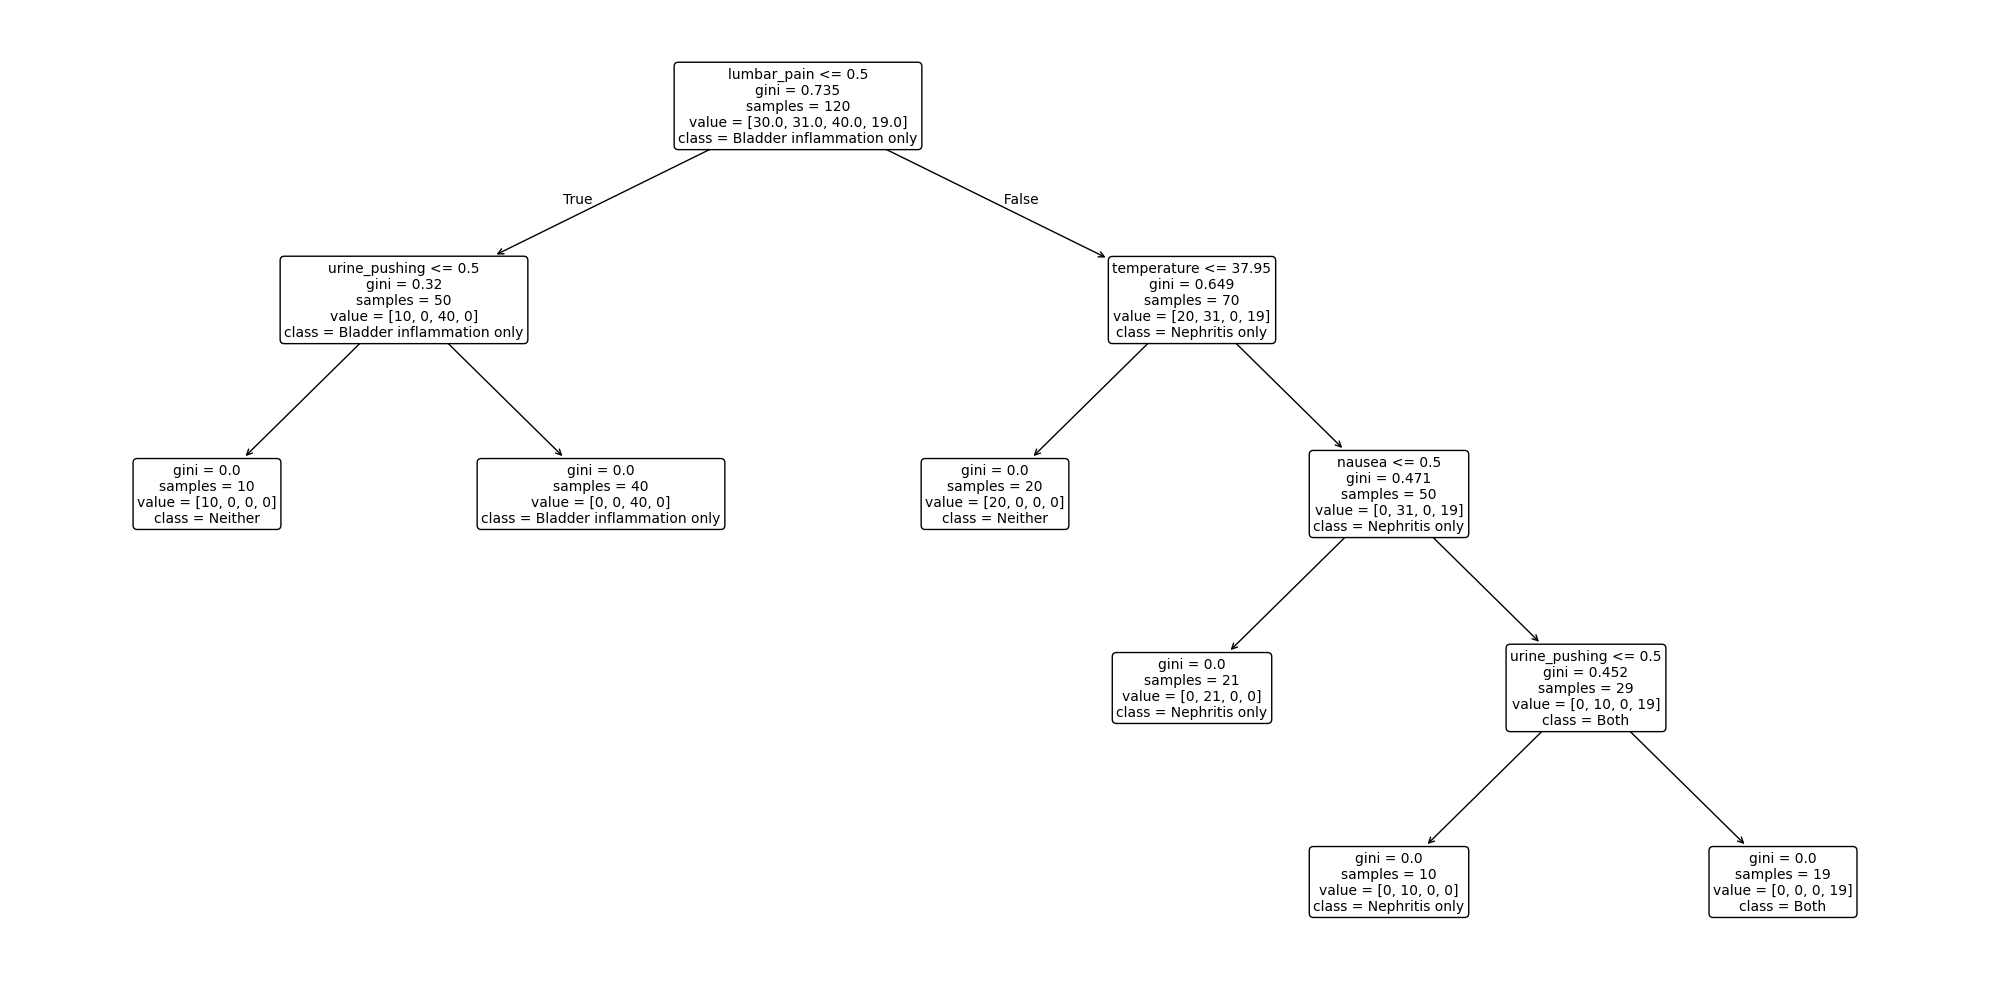

IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN Neither
IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN Bladder inflammation only
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN Neither
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea <= 0.50 THEN Nephritis only
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing <= 0.50 THEN Nephritis only
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing > 0.50 THEN Both


In [9]:
path = tree.cost_complexity_pruning_path(X, y)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {"ccp_alpha": np.unique(path.ccp_alphas)},
    scoring="accuracy",
    cv=cv
)
search.fit(X, y)

results = pd.DataFrame({
    "alpha": search.cv_results_["param_ccp_alpha"].astype(float),
    "cv_accuracy": search.cv_results_["mean_test_score"]
})

best_accuracy = results["cv_accuracy"].max()
chosen_alpha = results.loc[
    results["cv_accuracy"] == best_accuracy, "alpha"
].max()

pruned_tree = DecisionTreeClassifier(
    ccp_alpha=chosen_alpha,
    random_state=42
)
pruned_tree.fit(X, y)

display(results)
print("Selected alpha:", chosen_alpha)
print("Original leaves:", tree.get_n_leaves())
print("Pruned leaves:", pruned_tree.get_n_leaves())
print("Training accuracy:", pruned_tree.score(X, y))

plt.figure(figsize=(20, 10))
plot_tree(
    pruned_tree,
    feature_names=X.columns.tolist(),
    class_names=[class_labels[c] for c in pruned_tree.classes_],
    filled=False,
    rounded=True,
    fontsize=10
)
plt.tight_layout()
plt.show()

print_rules(pruned_tree, X.columns.tolist())

Cross-validation selected alpha = 0, so the original tree was retained.
The tree kept 6 leaves with 99.17% CV accuracy and 100% training accuracy

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [10]:
with open("communities.names") as f:
    community_columns = [
        line.split()[1]
        for line in f
        if line.startswith("@attribute")
    ]

communities = pd.read_csv(
    "communities.data",
    header=None,
    names=community_columns,
    na_values="?"
)

train = communities.iloc[:1495].copy()
test = communities.iloc[1495:].copy()

display(train.head())

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


### (b) Missing values

In [11]:
drop_columns = [
    "state", "county", "community", "communityname", "fold"
]
target = "ViolentCrimesPerPop"

X_train_raw = train.drop(columns=drop_columns + [target])
X_test_raw = test.drop(columns=drop_columns + [target])

y_train = train[target]
y_test = test[target]

imputer = SimpleImputer(strategy="mean")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train_raw),
    columns=X_train_raw.columns,
    index=X_train_raw.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=X_test_raw.columns,
    index=X_test_raw.index
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Training missing values:", X_train.isna().sum().sum())
print("Test missing values:", X_test.isna().sum().sum())

Training shape: (1495, 122)
Test shape: (499, 122)
Training missing values: 0
Test missing values: 0


### (c) Plot a correlation matrix

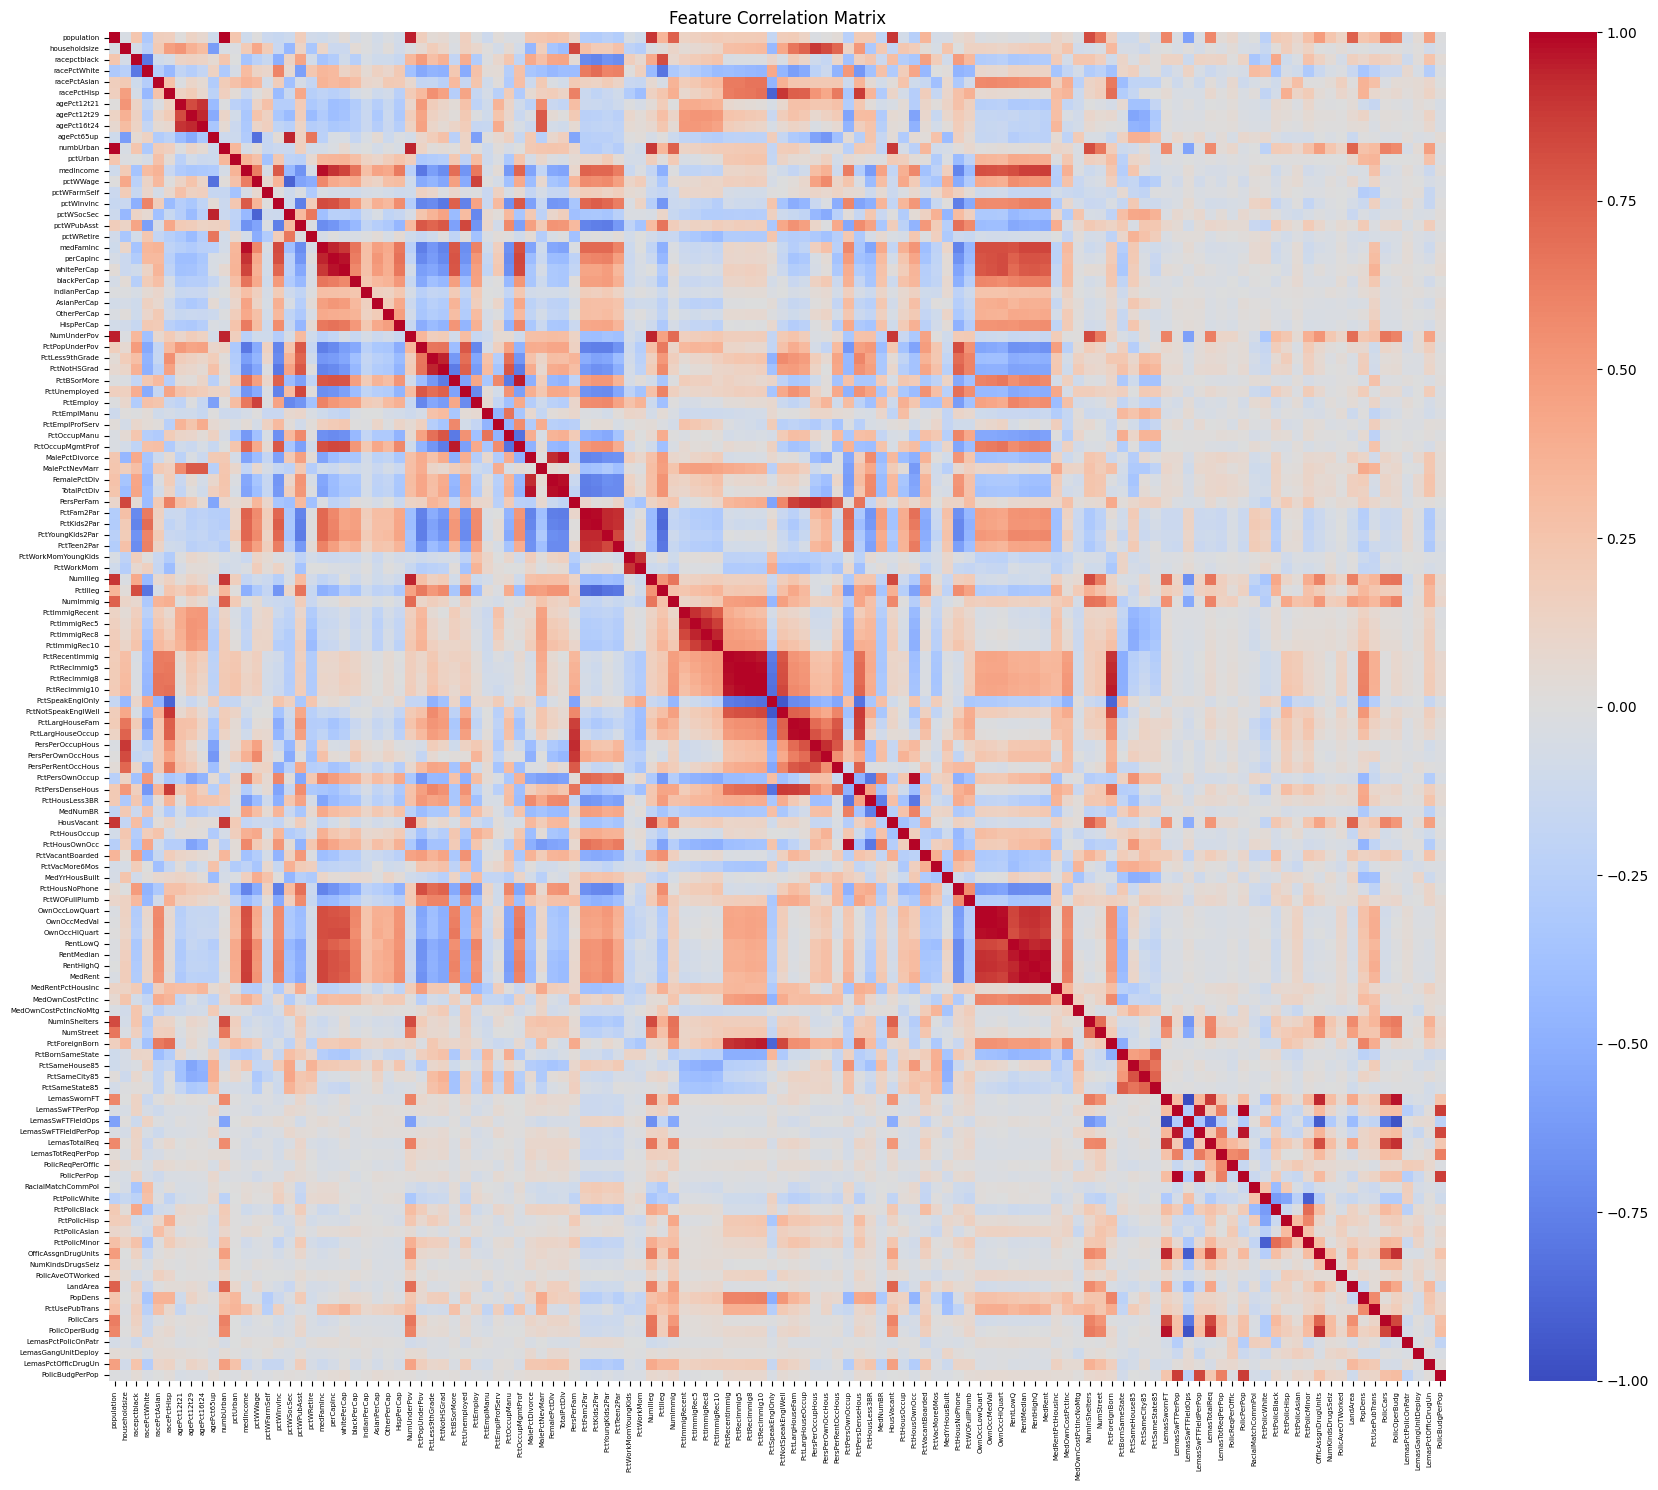

In [12]:
correlation = X_train.corr()

plt.figure(figsize=(18, 15))
sns.heatmap(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=True,
    yticklabels=True
)
plt.xticks(fontsize=5)
plt.yticks(fontsize=5)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [13]:
feature_cv = (
    X_train.std(ddof=1)
    / X_train.mean().replace(0, np.nan)
).sort_values(ascending=False)

with pd.option_context("display.max_rows", None):
    display(feature_cv.to_frame(name="CV"))

,CV
NumStreet,4.292923
NumInShelters,3.470952
NumIlleg,3.058964
NumImmig,2.926635
LemasPctOfficDrugUn,2.552946
NumUnderPov,2.342443
population,2.241105
numbUrban,2.038461
HousVacant,1.968467
LandArea,1.645408


### (e) Scatter plots and box plots for highest CV features

['NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'numbUrban', 'HousVacant', 'LandArea', 'racePctHisp']


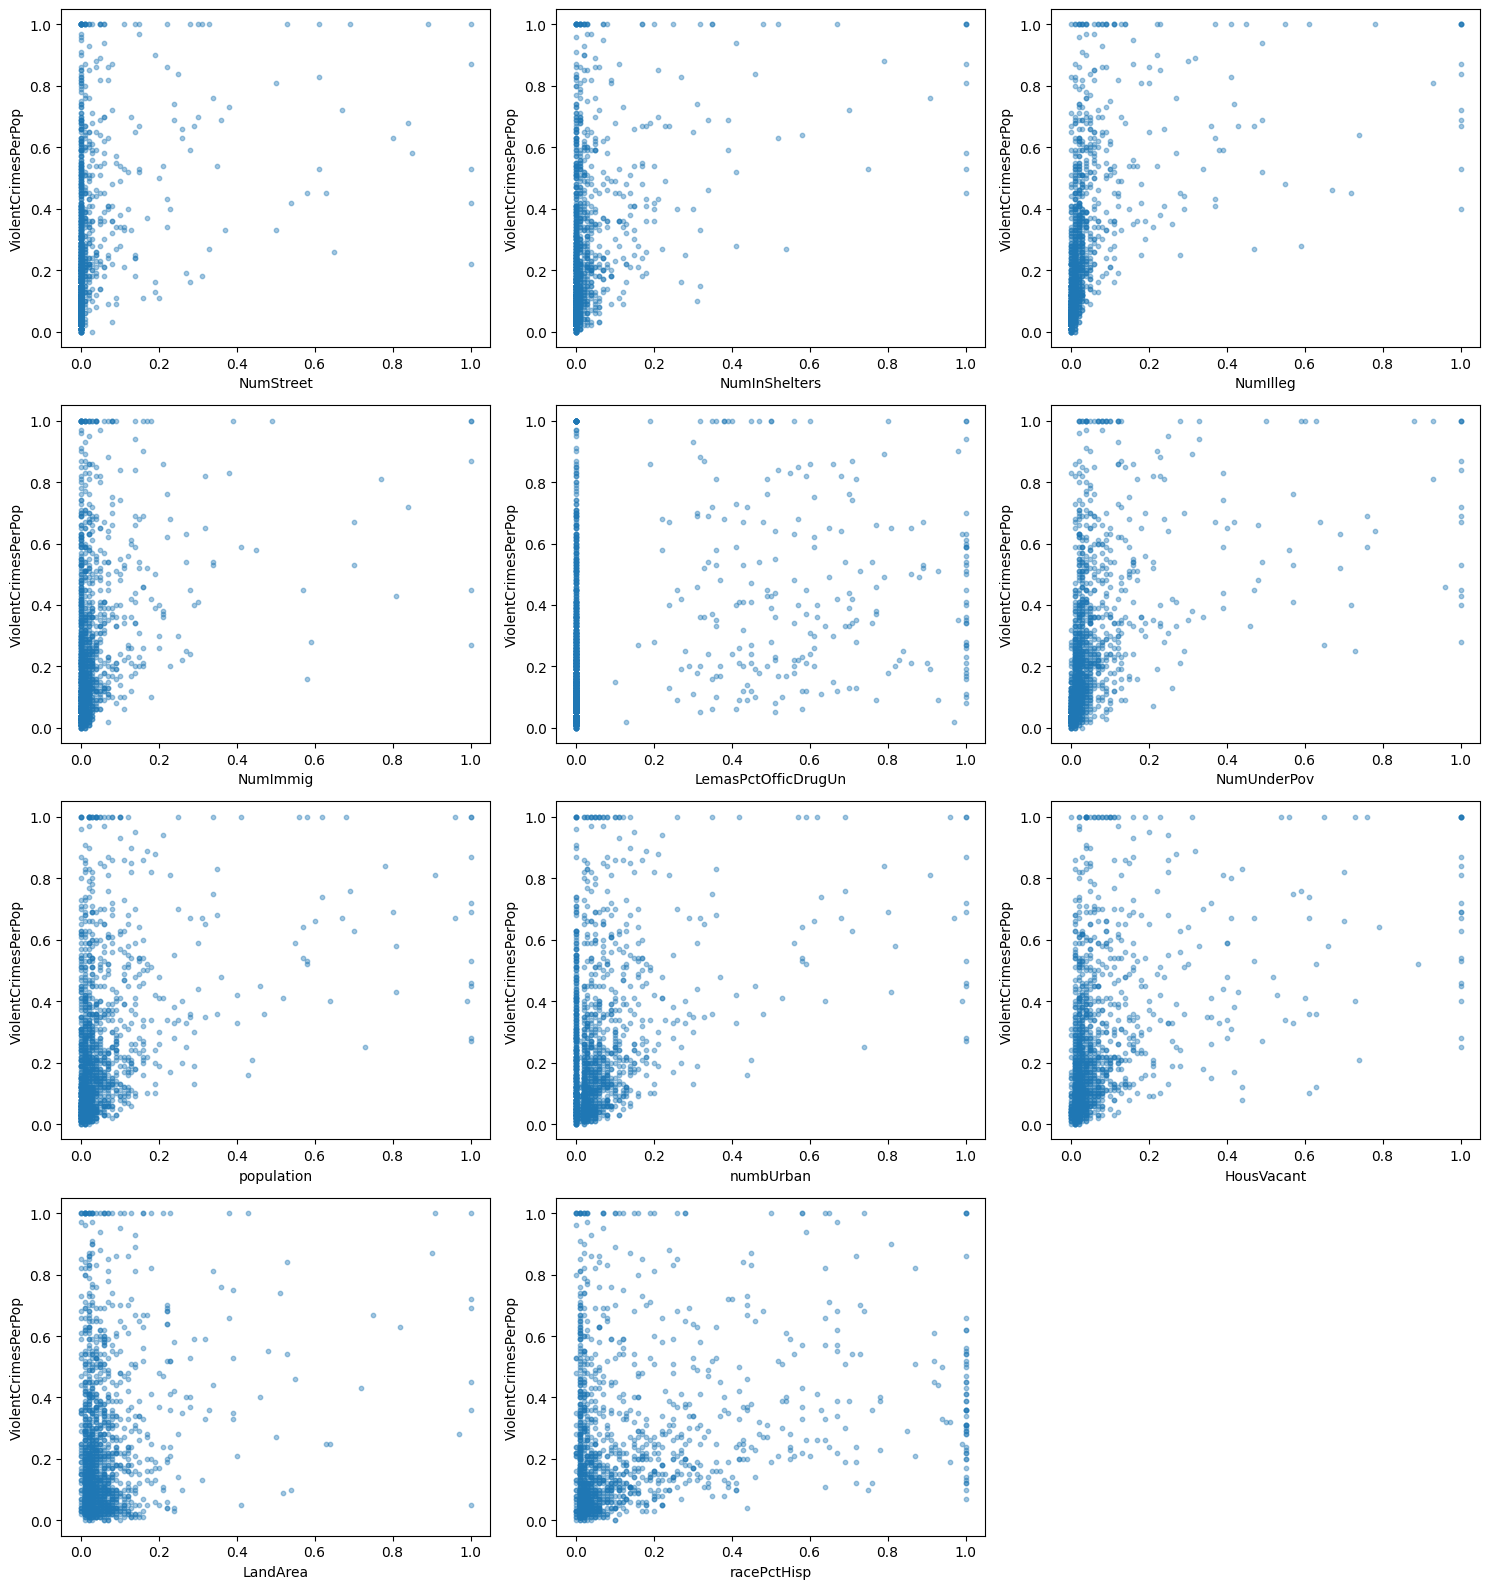

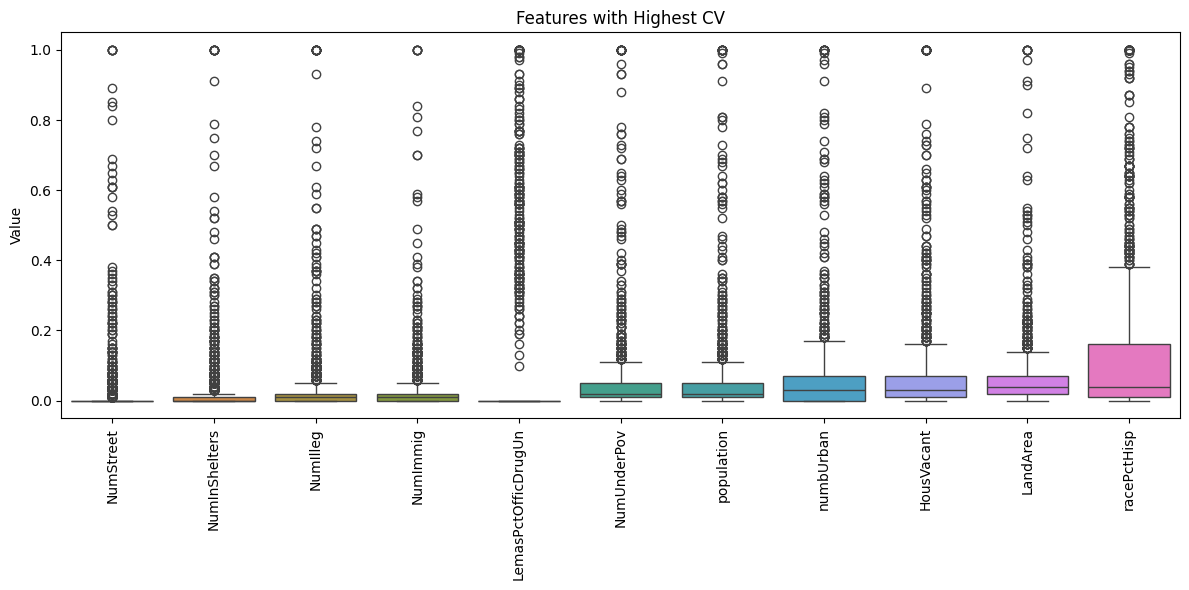

In [14]:
top_features = feature_cv.head(11).index
print(top_features.tolist())

fig, axes = plt.subplots(4, 3, figsize=(15, 16))

for ax, feature in zip(axes.flat, top_features):
    ax.scatter(X_train[feature], y_train, s=10, alpha=0.4)
    ax.set_xlabel(feature)
    ax.set_ylabel("ViolentCrimesPerPop")

axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
sns.boxplot(data=X_train[top_features])
plt.xticks(rotation=90)
plt.ylabel("Value")
plt.title("Features with Highest CV")
plt.tight_layout()
plt.show()

Scatter plots only can show the pattern of feeatures but cannot show the significance.

### (f) Fit a linear model

In [15]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)
linear_mse = mean_squared_error(y_test, linear_predictions)

print("Linear regression MSE:", linear_mse)

Linear regression MSE: 0.018141971135530104


### (g) Fit a ridge regression model

In [16]:
cv = KFold(n_splits=10, shuffle=True, random_state=42)

ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

ridge_search = GridSearchCV(
    ridge_pipeline,
    {"ridge__alpha": np.logspace(-4, 4, 100)},
    scoring="neg_mean_squared_error",
    cv=cv
)
ridge_search.fit(X_train_raw, y_train)

ridge_predictions = ridge_search.predict(X_test_raw)
ridge_mse = mean_squared_error(y_test, ridge_predictions)

print("Best lambda:", ridge_search.best_params_["ridge__alpha"])
print("Ridge test MSE:", ridge_mse)

Best lambda: 138.48863713938746
Ridge test MSE: 0.017461268145436637


### (h) Fit a LASSO model

In [17]:
lasso_results = []
lasso_models = {}

for name, scaler in [
    ("Unstandardized", "passthrough"),
    ("Standardized", StandardScaler())
]:
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", scaler),
        ("lasso", Lasso(max_iter=100000))
    ])

    search = GridSearchCV(
        pipeline,
        {"lasso__alpha": np.logspace(-5, 0, 100)},
        scoring="neg_mean_squared_error",
        cv=cv
    )
    search.fit(X_train_raw, y_train)

    predictions = search.predict(X_test_raw)
    mse = mean_squared_error(y_test, predictions)

    coefficients = search.best_estimator_.named_steps["lasso"].coef_
    selected = X_train_raw.columns[coefficients != 0].tolist()

    lasso_models[name] = search.best_estimator_
    lasso_results.append({
        "Model": name,
        "Best lambda": search.best_params_["lasso__alpha"],
        "Test MSE": mse,
        "Selected variables": len(selected)
    })

    print(name, "variables:", selected)
    print()

display(pd.DataFrame(lasso_results))

Unstandardized variables: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctBornSameState', 'PctSameC

,Model,Best lambda,Test MSE,Selected variables
0,Unstandardized,0.000129,0.017727,75
1,Standardized,0.000658,0.017841,76


Unstandardized LASSO selected 75 variables, with test MSE = 0.017727.
Standardized LASSO selected 76 variables, with test MSE = 0.017841.
Both performed similarly. Unstandardized LASSO had slightly lower test error.

### (i) Fit a PCR model

In [18]:
pcr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
    ("pca", PCA(svd_solver="full")),
    ("regression", LinearRegression())
])

pcr_search = GridSearchCV(
    pcr_pipeline,
    {"pca__n_components": range(1, X_train_raw.shape[1] + 1)},
    scoring="neg_mean_squared_error",
    cv=cv
)
pcr_search.fit(X_train_raw, y_train)

pcr_predictions = pcr_search.predict(X_test_raw)
pcr_mse = mean_squared_error(y_test, pcr_predictions)

print("Best M:", pcr_search.best_params_["pca__n_components"])
print("PCR test MSE:", pcr_mse)

Best M: 96
PCR test MSE: 0.018425436298895564


### (j) Fit a boosting tree

In [19]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [21]:
from xgboost import XGBRegressor

boost_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("boost", XGBRegressor(
        objective="reg:squarederror",
        booster="gbtree",
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        random_state=42,
        n_jobs=1
    ))
])

boost_search = GridSearchCV(
    boost_pipeline,
    {"boost__reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10, 100]},
    scoring="neg_mean_squared_error",
    cv=cv
)
boost_search.fit(X_train_raw, y_train)

boost_predictions = boost_search.predict(X_test_raw)
boost_mse = mean_squared_error(y_test, boost_predictions)

print("Best alpha:", boost_search.best_params_["boost__reg_alpha"])
print("Boosting test MSE:", boost_mse)

Best alpha: 0.01
Boosting test MSE: 0.01589973092741912


The boosting model had the lowest test MSE among the models tested.